<p class="lead">A graph is the right data structure when the information is in the relations rather than in the rows:
which compounds hit which targets, which proteins interact, which molecules resemble which. This unit builds the
laboratory's own drug-target network from a frozen ChEMBL extraction - 602 compounds, 479 human proteins and 16,047
measured activities - and then does to it what should be done to every network before it is interpreted: measure it,
compare it with a null model that preserves what is trivial about it, test a specific hypothesis with a permutation,
and evaluate link prediction with the same protocol discipline the modelling units imposed on regression. Two
selection biases are built into the data and are measured here rather than hidden. The recurring lesson is that
network statistics are almost never interpretable on their own: a projection with 100,146 edges means nothing until
it is thresholded, and a link-prediction AUC of 0.92 falls to 0.57 when the negatives are chosen honestly.</p>

<div class="box"><h4>Resumen en español</h4>
<p>Esta unidad representa relaciones biomédicas como grafos con NetworkX y las analiza con rigor estadístico. Se
construye el grafo bipartito fármaco-diana a partir de una tabla medida de ChEMBL (602 compuestos, 479 proteínas
humanas, 16.047 actividades; el 93 % de los compuestos se une a más de una diana), se describen sus distribuciones de
grado y sus centralidades, y se proyecta sobre las dianas: la proyección sin filtrar tiene densidad 0,875, de modo que
hace falta extraer un esqueleto por coeficiente de Jaccard antes de interpretarla. Las comunidades detectadas por
modularidad voraz son casi exclusivamente quinasas, lo que refleja el origen del conjunto de datos. Todos los
estadísticos se contrastan con un modelo nulo bipartito que preserva el grado (12.810 aristas del esqueleto
observadas frente a 2.161 ± 110 aleatorizadas). La pregunta de selectividad ROCK1 frente a ROCK2 se responde
directamente con los 276 compuestos medidos en ambas dianas: diferencia media de -0,50 unidades logarítmicas,
correlación 0,87 y solo un 16 % de compuestos con más de diez veces de diferencia. La predicción de enlaces alcanza
0,918 de AUC con negativos uniformes y 0,566 con negativos emparejados por grado. Finalmente se comparan la
similitud química y el reparto de dianas, y se discuten dos sesgos explícitos: los compuestos se eligieron por ser
ligandos de ROCK1, y el grado mide sobre todo cuánto se ha ensayado cada compuesto.</p></div>

<div class="box key"><h4>Learning objectives</h4>
<ul class="objectives">
<li>Represent biomedical relations as graphs in NetworkX and compute the basic descriptors: degree, components, clustering, shortest paths and the common centralities, knowing when each is defined.</li>
<li>Project a bipartite drug-target graph onto its two sides, threshold the projection into an interpretable backbone, and read the result as a polypharmacology or selectivity statement.</li>
<li>Detect communities and interpret them against external annotation, allowing for the resolution limit, for missing annotation and for the modularity of random graphs.</li>
<li>Assess any network statistic against a null model that preserves the degree sequence, and test a specific neighbourhood hypothesis with a permutation.</li>
<li>Evaluate link-prediction baselines with an honest negative set, measure the selection biases of the data, and decide when a network figure adds nothing.</li>
</ul></div>

<div class="box bridge"><h4>How to read this notebook</h4>
<p>Read it linearly with the code running; every number in the prose is printed by a cell of this notebook. In Google
Colab run <code>!pip install rdkit networkx</code> once before the setup cell; the unit uses
NetworkX<sup class="c"><a href="#r26">[26]</a></sup>, NumPy<sup class="c"><a href="#r30">[30]</a></sup>,
SciPy<sup class="c"><a href="#r31">[31]</a></sup>, scikit-learn<sup class="c"><a href="#r33">[33]</a></sup>,
matplotlib<sup class="c"><a href="#r32">[32]</a></sup> and RDKit. This is an <b>extended</b> unit for students
working on target prioritisation, selectivity or systems-level questions. <b>Nothing is downloaded</b>: the graphs
come from frozen tables, and the places where a real project would obtain a protein-protein or knowledge graph -
STRING<sup class="c"><a href="#r7">[7]</a></sup>, Open Targets<sup class="c"><a href="#r20">[20]</a></sup>,
Hetionet<sup class="c"><a href="#r6">[6]</a></sup> - are named but not queried. The unit uses the fingerprints of
<a href="../U13_Features_Dimensionality/index.html">Unit 13</a>, the clustering of
<a href="../U15_Clustering/index.html">Unit 15</a>, the evaluation protocol of
<a href="../U12_Validation/index.html">Unit 12</a> and the permutation logic of
<a href="../U8_Hypothesis_Testing/index.html">Unit 8</a>; it runs in about two minutes.</p></div>

In [1]:
# Setup. In Google Colab run once:  !pip install rdkit networkx
from pathlib import Path
import urllib.request, warnings, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import scipy, sklearn, networkx as nx, rdkit
from scipy.stats import rankdata, spearmanr
from networkx.algorithms import bipartite as bp
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import rdFingerprintGenerator
RDLogger.DisableLog("rdApp.*")
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="FigureCanvasAgg is non-interactive")
np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10,
                     "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})

REPO = "DanielBustosG/DanielBustosG.github.io"   # GitHub repository hosting this course (set once in common/config.json and here)
DATA_URL = f"https://raw.githubusercontent.com/{REPO}/main/DataScience/data/"
def data_path(name):
    '''Local ../data/<name> when the notebook runs from its course folder; otherwise (Colab) download once.'''
    local = Path("..") / "data" / name
    if local.exists():
        return local
    dest = Path("data") / name
    if not dest.exists():
        dest.parent.mkdir(exist_ok=True)
        urllib.request.urlretrieve(DATA_URL + name, dest)
    return dest
def load_data(name, **kw):
    return pd.read_csv(data_path(name), **kw)

print("numpy", np.__version__, "| pandas", pd.__version__, "| networkx", nx.__version__,
      "| rdkit", rdkit.__version__, "| scipy", scipy.__version__)

numpy 2.4.6 | pandas 3.0.3 | networkx 3.6.1 | rdkit 2026.03.4 | scipy 1.17.1


## 1. What the laboratory means by a network

<div class="box bridge"><h4>Domain context</h4>
<p>A <b>graph</b> is a set of <b>nodes</b> joined by <b>edges</b>. In drug discovery the nodes are usually compounds,
proteins, diseases or genes. A <b>drug-target network</b> joins a compound to every protein it is known to act
on<sup class="c"><a href="#r3">[3]</a></sup>; it is <b>bipartite</b>, meaning edges only ever run between the two
kinds of node. An edge here means a measured affinity: <b>pChEMBL</b> is -log<sub>10</sub> of the molar concentration
at which the compound acts (IC50, Ki or Kd), so 7 means 100 nM and each unit is a factor of ten.
<b>Polypharmacology</b> is the observation that most drugs bind several proteins<sup class="c"><a href="#r2">[2]</a></sup>,
sometimes as the mechanism of action and sometimes as the mechanism of a side effect; <b>hERG</b>, a cardiac
potassium channel, is the classic unwanted target. The opposite property, <b>selectivity</b>, is what a project wants
when the off-target is harmful - and the hardest case is a close <b>isoform</b>, two proteins from the same gene
family with nearly identical binding sites, such as <b>ROCK1</b> and <b>ROCK2</b>, the two Rho-associated kinases the
group works on. A <b>protein-protein interaction (PPI) network</b> joins proteins that interact physically or
functionally; <b>network medicine</b><sup class="c"><a href="#r1">[1]</a></sup> studies disease through
neighbourhoods of such a graph. A <b>chemical-similarity network</b> joins two molecules whose fingerprint similarity
exceeds a threshold, and a <b>Murcko scaffold</b><sup class="c"><a href="#r27">[27]</a></sup> is the ring framework of
a molecule, the usual label of a chemical series.</p></div>

The network analysed here is measured, not inferred. `drug_target_edges.csv` holds 16,047 activity records from
ChEMBL<sup class="c"><a href="#r28">[28]</a></sup>: for each of 602 well-characterised ROCK1 compounds, every human
single-protein target at which it has a pChEMBL value, with the median potency and the number of measurements behind
it. `drug_target_targets.csv` describes the 479 targets. Two properties of the extraction must be stated before any
interpretation, and both become exercises below.

<ol>
<li><b>It is a ROCK neighbourhood, not pharmacological space.</b> The compounds entered the table because they are
ROCK1 ligands, so the targets that appear are the ones ROCK inhibitors were tested against - overwhelmingly other
kinases. Nothing here licenses a statement about drugs in general.</li>
<li><b>Degree partly measures assay effort.</b> A compound linked to 300 targets has usually been through a kinase
selectivity panel; a compound linked to two has not. Absence of an edge is absence of a measurement, not evidence of
inactivity.</li>
</ol>

In [2]:
edges = load_data("drug_target_edges.csv")
targets_tab = load_data("drug_target_targets.csv")
print("edges:", edges.shape, "| targets table:", targets_tab.shape)
print(edges.head(3).to_string(index=False))
compounds = sorted(edges["molecule_chembl_id"].unique())
targets = sorted(edges["target_chembl_id"].unique())
B = nx.Graph()
B.add_nodes_from(compounds, bipartite=0)
B.add_nodes_from(targets, bipartite=1)
B.add_weighted_edges_from(edges[["molecule_chembl_id", "target_chembl_id", "pchembl_median"]]
                          .itertuples(index=False, name=None))
print("\nbipartite graph: %d nodes (%d compounds + %d targets), %d edges, density %.4f, %d connected component(s)"
      % (B.number_of_nodes(), len(compounds), len(targets), B.number_of_edges(), nx.density(B),
         nx.number_connected_components(B)))
cdeg = np.array([B.degree(c) for c in compounds]); tdeg = np.array([B.degree(t) for t in targets])
print("compound degree: median %d, mean %.1f, max %d | %d of %d compounds (%.0f %%) bind more than one target"
      % (np.median(cdeg), cdeg.mean(), cdeg.max(), (cdeg > 1).sum(), len(cdeg), 100 * (cdeg > 1).mean()))
print("target degree  : median %d, mean %.1f, max %d | %d targets have fewer than 10 compounds"
      % (np.median(tdeg), tdeg.mean(), tdeg.max(), (tdeg < 10).sum()))
tname = dict(zip(targets_tab["target_chembl_id"], targets_tab["target_name"]))
print("\nbusiest targets:")
for t in sorted(targets, key=lambda x: -B.degree(x))[:6]:
    print("   %-12s %-56s %4d compounds" % (t, str(tname.get(t))[:56], B.degree(t)))

edges: (16047, 4) | targets table: (479, 6)
molecule_chembl_id target_chembl_id  pchembl_median  n_measurements
          CHEMBL10       CHEMBL1824           4.720               1
          CHEMBL10       CHEMBL1862           5.495               2
          CHEMBL10       CHEMBL1906           6.340               7

bipartite graph: 1081 nodes (602 compounds + 479 targets), 16047 edges, density 0.0275, 1 connected component(s)
compound degree: median 5, mean 26.7, max 386 | 560 of 602 compounds (93 %) bind more than one target
target degree  : median 26, mean 33.5, max 344 | 83 targets have fewer than 10 compounds

busiest targets:
   CHEMBL3231   Rho-associated protein kinase 1                           344 compounds
   CHEMBL2973   Rho-associated protein kinase 2                           310 compounds
   CHEMBL2041   Proto-oncogene tyrosine-protein kinase receptor Ret       130 compounds
   CHEMBL1974   Receptor-type tyrosine-protein kinase FLT3                127 compounds
   CHEMBL

In [3]:
ROCK1, ROCK2 = "CHEMBL3231", "CHEMBL2973"
print("pChEMBL values: range %.2f to %.2f, median %.2f"
      % (edges["pchembl_median"].min(), edges["pchembl_median"].max(), edges["pchembl_median"].median()))
print("edges that touch ROCK1 or ROCK2: %.1f %% of all edges"
      % (100 * (B.degree(ROCK1) + B.degree(ROCK2)) / B.number_of_edges()))
kinase_like = np.array(["kinase" in str(tname.get(t, "")).lower() for t in targets])
print("targets whose NAME contains 'kinase': %d of %d (%.0f %%); they carry %.0f %% of all edges"
      % (kinase_like.sum(), len(targets), 100 * kinase_like.mean(),
         100 * sum(B.degree(t) for t, k in zip(targets, kinase_like) if k) / B.number_of_edges()))
print("ChEMBL protein_class annotation present for %d of %d targets"
      % (targets_tab["protein_class"].notna().sum(), len(targets_tab)))

n_meas = edges.groupby("molecule_chembl_id")["n_measurements"].sum()
deg_c = edges.groupby("molecule_chembl_id").size()
print("\nassay-effort bias: Spearman(compound degree, total measurements) = %.3f"
      % spearmanr(deg_c, n_meas).statistic)
print("                   Spearman(target degree, total measurements)   = %.3f"
      % spearmanr(edges.groupby("target_chembl_id").size(),
                  edges.groupby("target_chembl_id")["n_measurements"].sum()).statistic)

pChEMBL values: range 3.65 to 10.22, median 6.10
edges that touch ROCK1 or ROCK2: 4.1 % of all edges
targets whose NAME contains 'kinase': 377 of 479 (79 %); they carry 83 % of all edges
ChEMBL protein_class annotation present for 0 of 479 targets

assay-effort bias: Spearman(compound degree, total measurements) = 0.925
                   Spearman(target degree, total measurements)   = 0.943


The extraction is a single connected component of 1,081 nodes: every compound reaches every other through shared
targets. Ninety-three per cent of the compounds bind more than one target - genuine, measured polypharmacology, which
is what the previous version of this analysis could only infer from chemical similarity. The degree distributions are
extremely skewed on both sides: the median compound has 5 targets and the busiest has 386, the median target has 26
compounds and ROCK1 has 344.

The two biases are now numbers rather than warnings. Targets whose name contains "kinase" make up 79 % of the nodes
and carry 83 % of the edges, so this graph is a kinase graph; and the rank correlation between a compound's degree
and the total number of measurements behind its edges is **0.93**, so degree is very largely a record of how much
work has been done on a compound. Note also that ChEMBL's `protein_class` column is empty for all 479 targets in this
export - a complete annotation gap, which section 4 has to work around with the target names themselves rather than
pretending the annotation exists.

<div class="exercise"><h4>Exercise 1</h4>
<p>Quantify the ROCK-neighbourhood bias. Compute, for every target, the fraction of its compounds that are also
measured at ROCK1, and plot that fraction against the target's degree. Then remove ROCK1 and ROCK2 from the graph and
recompute the number of connected components and the median compound degree. How much of the graph's connectivity is
carried by the two targets the data set was built around, and what would you have to collect to turn this into a
sample of pharmacological space?</p></div>

## 2. Degrees, centralities and what they mean in a bipartite graph

In [4]:
t0 = time.time()
btw = nx.betweenness_centrality(B, k=120, seed=0, normalized=True)
eig = nx.eigenvector_centrality_numpy(B)
print("betweenness (120 pivots) and eigenvector centrality in %.1f s" % (time.time() - t0))
print("\ntop betweenness overall:")
for n in sorted(btw, key=btw.get, reverse=True)[:6]:
    kind = "target  " if n in set(targets) else "compound"
    print("   %s %-13s degree %4d | betweenness %.4f | %s" % (kind, n, B.degree(n), btw[n], str(tname.get(n, ""))[:40]))
print("top eigenvector centrality among targets:")
for n in [x for x in sorted(eig, key=eig.get, reverse=True) if x in set(targets)][:4]:
    print("   %-13s degree %4d | eigenvector %.3f | %s" % (n, B.degree(n), eig[n], str(tname.get(n, ""))[:46]))
print("\nSpearman(degree, betweenness) over all nodes: %.3f"
      % spearmanr([B.degree(n) for n in B], [btw[n] for n in B]).statistic)
print("bipartite average clustering (dot mode): %.3f" % bp.average_clustering(B, mode="dot"))

betweenness (120 pivots) and eigenvector centrality in 0.5 s

top betweenness overall:
   target   CHEMBL3231    degree  344 | betweenness 0.2196 | Rho-associated protein kinase 1
   target   CHEMBL2973    degree  310 | betweenness 0.2103 | Rho-associated protein kinase 2
   compound CHEMBL388978  degree  386 | betweenness 0.0602 | 
   compound CHEMBL4097778 degree  329 | betweenness 0.0531 | 
   compound CHEMBL4549667 degree  291 | betweenness 0.0480 | 
   compound CHEMBL603469  degree  351 | betweenness 0.0433 | 
top eigenvector centrality among targets:
   CHEMBL1974    degree  127 | eigenvector 0.080 | Receptor-type tyrosine-protein kinase FLT3
   CHEMBL258     degree  112 | eigenvector 0.074 | Tyrosine-protein kinase Lck
   CHEMBL2041    degree  130 | eigenvector 0.074 | Proto-oncogene tyrosine-protein kinase recepto
   CHEMBL1862    degree  112 | eigenvector 0.073 | Tyrosine-protein kinase ABL1

Spearman(degree, betweenness) over all nodes: 0.910
bipartite average clustering (dot

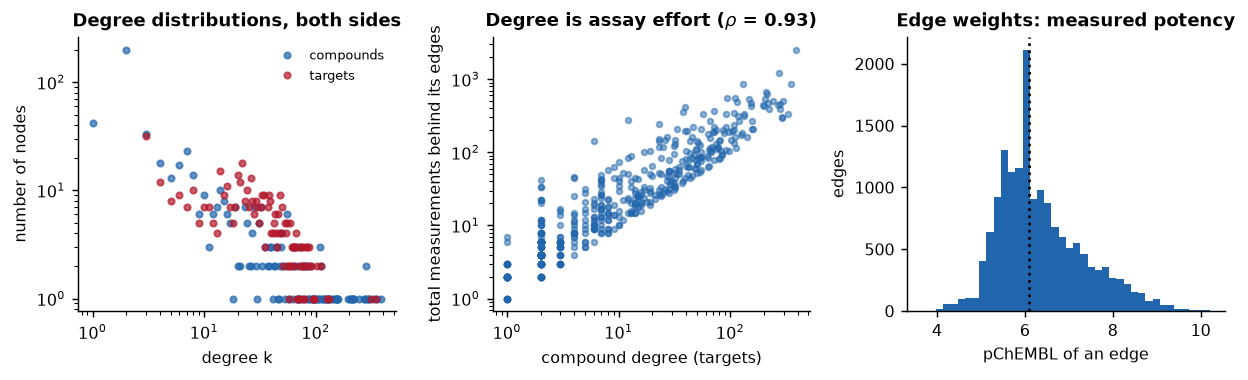

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(9.6, 3.0))
for ax, d, lab, col in [(axes[0], cdeg, "compounds", "#2166ac"), (axes[0], tdeg, "targets", "#b2182b")]:
    vals, counts = np.unique(d, return_counts=True)
    ax.loglog(vals, counts, "o", ms=3.5, alpha=0.7, color=col, label=lab)
axes[0].set_xlabel("degree k"); axes[0].set_ylabel("number of nodes")
axes[0].set_title("Degree distributions, both sides"); axes[0].legend(fontsize=7, frameon=False)
axes[1].scatter(deg_c.reindex(compounds).to_numpy(), n_meas.reindex(compounds).to_numpy(), s=10, alpha=0.5, color="#2166ac")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("compound degree (targets)"); axes[1].set_ylabel("total measurements behind its edges")
axes[1].set_title(r"Degree is assay effort ($\rho$ = 0.93)")
axes[2].hist(edges["pchembl_median"], bins=40, color="#2166ac")
axes[2].axvline(edges["pchembl_median"].median(), ls=":", c="k")
axes[2].set_xlabel("pChEMBL of an edge"); axes[2].set_ylabel("edges")
axes[2].set_title("Edge weights: measured potency")
fig.tight_layout(); plt.show()

<p class="caption"><b>Figure 1.</b> Left: both degree distributions are heavy-tailed on logarithmic axes - a few
compounds have been profiled against hundreds of targets and a few targets have been screened against hundreds of
compounds - but neither is a clean power law<sup class="c"><a href="#r15">[15]</a></sup>, and with 602 and 479 nodes
no such claim could be supported anyway. Centre: compound degree against the number of measurements behind its
edges, Spearman 0.93; the "most promiscuous" compounds are first of all the most assayed ones. Right: the pChEMBL
distribution of the edges, median 6.10, i.e. the typical recorded interaction is micromolar-to-submicromolar.</p>

Centrality in a bipartite graph needs care. Betweenness is dominated by ROCK1 (0.220) and ROCK2 (0.210), followed by
the four most-profiled compounds - exactly what a graph assembled around two targets must look like, and a reminder
that a centrality ranking reproduces the sampling design before it reveals biology. Eigenvector centrality, which is
defined here because the graph is connected, puts the tyrosine kinases FLT3 (0.080), LCK and RET (0.074) and ABL1
(0.073) at the top: they are the targets most often co-measured with the hubs, and the rank correlation between
degree and betweenness over all nodes is 0.91. The bipartite clustering coefficient is 0.223.

## 3. Projecting onto the targets, and why a projection must be thresholded

The bipartite graph answers questions about compounds and targets together. To ask *which targets share chemistry*,
project it: join two targets when at least one compound binds both. The weight can be the number of shared compounds
or - better, because it is scale-free - the Jaccard coefficient of their compound sets,
$|C_i \cap C_j| / |C_i \cup C_j|$.

The projection of a dense bipartite graph is nearly complete, and this one is no exception, so the first operation
after projecting is always to threshold. Keeping only edges above a Jaccard cut-off produces a **backbone**; the cut
is a free parameter and must be reported with the result, exactly like the similarity threshold of a chemical
network.

In [6]:
J = bp.overlap_weighted_projected_graph(B, targets)        # weight = Jaccard of the two compound sets
shared = bp.weighted_projected_graph(B, targets)           # weight = number of shared compounds
w_shared = np.array([d["weight"] for _, _, d in shared.edges(data=True)])
print("unthresholded target projection: %d nodes, %d edges, density %.3f"
      % (J.number_of_nodes(), J.number_of_edges(), nx.density(J)))
print("shared-compound weights: median %d, 90th percentile %d, maximum %d"
      % (np.median(w_shared), np.percentile(w_shared, 90), w_shared.max()))
print("\nJaccard threshold   edges   density   isolated targets   components")
for thr in (0.2, 0.3, 0.4, 0.5):
    H = nx.Graph((u, v, d) for u, v, d in J.edges(data=True) if d["weight"] >= thr)
    H.add_nodes_from(J.nodes)
    print("        %.1f        %6d    %.3f          %3d              %3d"
          % (thr, H.number_of_edges(), nx.density(H), sum(1 for n in H if H.degree(n) == 0),
             nx.number_connected_components(H)))
print("\nROCK1 and ROCK2 share %d compounds (Jaccard %.3f)"
      % (shared[ROCK1][ROCK2]["weight"], J[ROCK1][ROCK2]["weight"]))
print("strongest links of the projection (shared compounds):")
for u, v, d in sorted(shared.edges(data=True), key=lambda e: -e[2]["weight"])[:5]:
    print("   %-34s -- %-34s %3d shared" % (str(tname.get(u))[:34], str(tname.get(v))[:34], d["weight"]))

unthresholded target projection: 479 nodes, 100146 edges, density 0.875
shared-compound weights: median 8, 90th percentile 21, maximum 276

Jaccard threshold   edges   density   isolated targets   components
        0.2         36284    0.317           20               27
        0.3         12810    0.112           42               51
        0.4          3452    0.030           72               97
        0.5           874    0.008          171              211

ROCK1 and ROCK2 share 276 compounds (Jaccard 0.730)
strongest links of the projection (shared compounds):
   Rho-associated protein kinase 2    -- Rho-associated protein kinase 1    276 shared
   Tyrosine-protein kinase ABL1       -- Tyrosine-protein kinase Lck         89 shared
   Receptor-type tyrosine-protein kin -- Tyrosine-protein kinase Lck         88 shared
   Receptor-type tyrosine-protein kin -- Proto-oncogene tyrosine-protein ki  88 shared
   Tyrosine-protein kinase ABL1       -- Proto-oncogene tyrosine-protein ki  

Jaccard weights of the unthresholded projection: median 0.154, 90th percentile 0.318, maximum 1.000


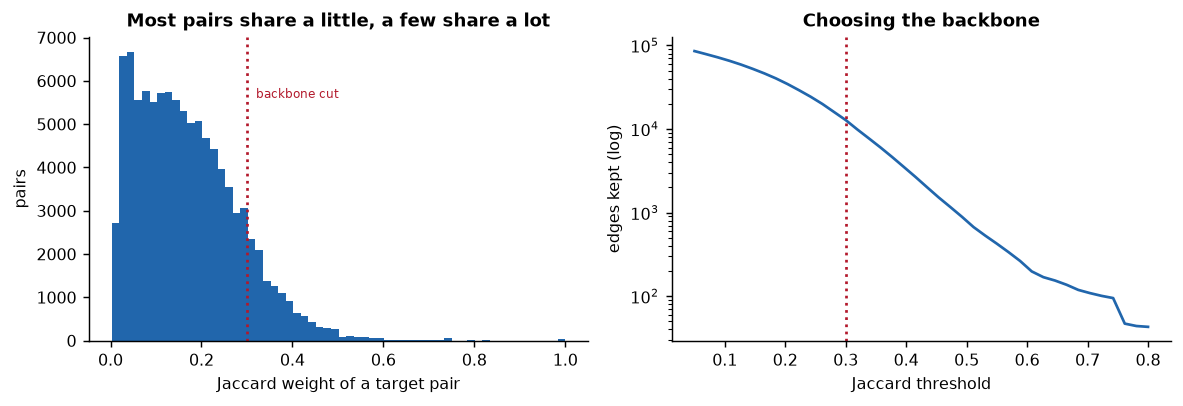

In [7]:
jw = np.array([d["weight"] for _, _, d in J.edges(data=True)])
ths = np.linspace(0.05, 0.8, 40)
n_edges = [int((jw >= x).sum()) for x in ths]
print("Jaccard weights of the unthresholded projection: median %.3f, 90th percentile %.3f, maximum %.3f"
      % (np.median(jw), np.percentile(jw, 90), jw.max()))
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.2))
axes[0].hist(jw, bins=60, color="#2166ac")
axes[0].axvline(0.3, ls=":", c="#b2182b")
axes[0].text(0.32, axes[0].get_ylim()[1] * 0.8, "backbone cut", fontsize=6.5, color="#b2182b")
axes[0].set_xlabel("Jaccard weight of a target pair"); axes[0].set_ylabel("pairs")
axes[0].set_title("Most pairs share a little, a few share a lot")
axes[1].semilogy(ths, n_edges, color="#2166ac")
axes[1].axvline(0.3, ls=":", c="#b2182b")
axes[1].set_xlabel("Jaccard threshold"); axes[1].set_ylabel("edges kept (log)")
axes[1].set_title("Choosing the backbone")
fig.tight_layout(); plt.show()

<p class="caption"><b>Figure 2.</b> Left: the distribution of Jaccard weights over the 100,146 target pairs that share at least one compound (of the 114,481 pairs 479 targets admit; the remaining 14,335 share none and carry weight zero) - median
0.154, ninetieth percentile 0.318, maximum 1.000 - showing that the projection is dense in weak links and sparse in
strong ones. Right: the number of edges surviving each threshold, on a logarithmic scale; the cut at 0.3 used below
is marked. There is no natural break in either plot, which is why the threshold is a declared choice and not a
discovery.</p>

Unthresholded, the projection has 100,146 edges among 479 targets - a density of 0.875, which is to say almost every
pair of targets shares at least one compound and the graph carries no usable structure. At Jaccard 0.3 the backbone
keeps 12,810 edges (density 0.112) and leaves 42 targets isolated; at 0.5 only 874 edges survive and 171 targets drop
out. We work at 0.3 and say so. The strongest single link is ROCK1 - ROCK2 with 276 shared compounds, which is the
pair the next section is about.

## 4. Communities and the annotation gap

Community detection partitions a graph into groups denser inside than between. Greedy modularity
maximisation<sup class="c"><a href="#r14">[14]</a></sup> optimises $Q$<sup class="c"><a href="#r12">[12]</a></sup>,
the fraction of edges inside communities minus the fraction expected in a degree-preserving random graph; Louvain
and Leiden<sup class="c"><a href="#r4">[4]</a></sup><sup class="c"><a href="#r5">[5]</a></sup> optimise the same
objective faster on larger graphs. Interpreting the communities requires external labels, and here the obvious label
is missing: ChEMBL's protein classification came back empty for every target in this export. The honest workaround is
to use the target names as a crude, text-matched surrogate and to say that is what we are doing.

In [8]:
backbone = nx.Graph((u, v, d) for u, v, d in J.edges(data=True) if d["weight"] >= 0.3)
backbone.add_nodes_from(J.nodes)
core = backbone.subgraph([n for n in backbone if backbone.degree(n) > 0]).copy()
communities = list(nx.community.greedy_modularity_communities(core))
Q = nx.community.modularity(core, communities)
print("backbone at Jaccard >= 0.3: %d targets, %d edges | %d communities, Q = %.3f"
      % (core.number_of_nodes(), core.number_of_edges(), len(communities), Q))
rows = []
for i, c in enumerate(sorted(communities, key=len, reverse=True)):
    names = [str(tname.get(t, t)) for t in c]
    kin = sum("kinase" in n.lower() for n in names)
    rows.append(dict(community=i, size=len(c), kinase_named="%.0f %%" % (100 * kin / len(c)),
                     example="; ".join(n[:34] for n in names[:2])))
print(pd.DataFrame(rows).head(8).to_string(index=False))
nonkin = [c for c in communities if sum("kinase" in str(tname.get(t, "")).lower() for t in c) == 0]
if nonkin:
    print("\nnon-kinase community members:", "; ".join(str(tname.get(t))[:38] for t in list(nonkin[0])[:6]))

backbone at Jaccard >= 0.3: 437 targets, 12810 edges | 17 communities, Q = 0.328
 community  size kinase_named                                                                example
         0   179         91 % STE20/SPS1-related proline-alanine; Interferon-induced, double-strande
         1   177         79 %                     Ephrin type-B receptor 4; TGF-beta receptor type-2
         2    27         89 % Serine/threonine-protein kinase PI; Dual specificity testis-specific p
         3    11        100 % Serine/threonine-protein kinase mT; Phosphatidylinositol 3-kinase cata
         4     8          0 %                            Carbonic anhydrase 12; Carbonic anhydrase 9
         5     7        100 % MAP kinase-activated protein kinas; Serine/threonine-protein kinase 36
         6     4        100 %         Protein kinase C iota type; Serine/threonine-protein kinase Sg
         7     4          0 %                               Cytochrome P450 3A4; Cytochrome P450 2C9

non-kinas

community sizes: [179, 177, 27, 11, 8, 7, 4, 4, 3, 3, 2, 2, 2, 2, 2, 2, 2]
kinase fraction per community: [0.91, 0.79, 0.89, 1.0, 0.0, 1.0, 1.0, 0.0, 0.67, 1.0, 0.0, 0.0, 1.0, 1.0, 0.0, 1.0, 0.0]


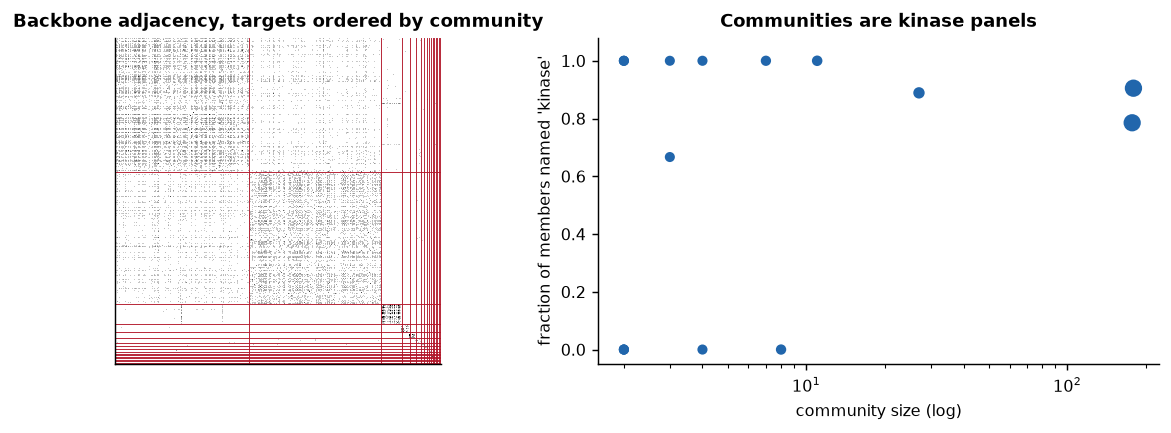

In [9]:
sizes = [len(c) for c in sorted(communities, key=len, reverse=True)]
kin_frac = [sum("kinase" in str(tname.get(t_, "")).lower() for t_ in c) / len(c)
            for c in sorted(communities, key=len, reverse=True)]
order = [t_ for c in sorted(communities, key=len, reverse=True) for t_ in c]
Adj = nx.to_numpy_array(core, nodelist=order)
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.4))
axes[0].imshow(Adj, cmap="Greys", interpolation="nearest")
edge_pos = np.cumsum(sizes)[:-1]
for e in edge_pos:
    axes[0].axhline(e, color="#b2182b", lw=0.5); axes[0].axvline(e, color="#b2182b", lw=0.5)
axes[0].set_xticks([]); axes[0].set_yticks([])
axes[0].set_title("Backbone adjacency, targets ordered by community")
axes[1].scatter(sizes, kin_frac, s=[20 + 0.3 * s for s in sizes], color="#2166ac")
axes[1].set_xscale("log"); axes[1].set_ylim(-0.05, 1.08)
axes[1].set_xlabel("community size (log)"); axes[1].set_ylabel("fraction of members named 'kinase'")
axes[1].set_title("Communities are kinase panels")
fig.tight_layout(); plt.show()
print("community sizes:", sizes)
print("kinase fraction per community:", [round(k, 2) for k in kin_frac])

<p class="caption"><b>Figure 3.</b> Left: the adjacency matrix of the 437-target backbone with rows and columns
ordered by community; the dense diagonal blocks are the communities and the off-diagonal density shows how much they
still share. Right: each community's size against the fraction of its members whose name contains "kinase" - the
four largest communities are 79-100 % kinases, while six small communities (sizes 8, 4, 2, 2, 2 and 2) contain no
kinase-named target at all; the largest of those six holds the carbonic anhydrases.</p>

Seventeen communities at Q = 0.328, and the two largest hold 179 and 177 targets of which 91 % and 79 % are named
"kinase". A small community of eight contains no kinase at all - six of its members are carbonic
anhydrases - and a four-member community holds cytochrome P450 isoforms: the counter-screens and
ADME assays that accompany a kinase programme. This is a correct description of the data and a poor description
of pharmacology - the communities recover the structure of a kinase selectivity panel, because that is what the
compounds were tested in. With a real protein-class annotation the same partition could be scored against a
reference labelling (an adjusted Rand index, as in Unit 15); with the annotation absent, a text match on the target
name and an explicit statement of its crudeness is as far as the data allow.

<div class="exercise"><h4>Exercise 2</h4>
<p>Rebuild the backbone at Jaccard 0.2 and 0.4, rerun the community detection and tabulate the number of
communities, the modularity and the kinase fraction of the largest community. Then check the resolution
limit<sup class="c"><a href="#r13">[13]</a></sup>: how small is the smallest community the algorithm returns at each
threshold, and could a four-target family be detected at all in a backbone of this size?</p></div>

## 5. Null models for a bipartite graph

Every number above - the density of the backbone, the modularity, the Jaccard of ROCK1 with ROCK2 - is shaped by the
degree sequence before it is shaped by biology. A target measured against 344 compounds will share compounds with
everything. The null model that removes that effect while keeping the degrees is **degree-preserving randomisation**:
repeatedly pick two edges and swap their endpoints<sup class="c"><a href="#r16">[16]</a></sup>. In a bipartite graph
the swap must exchange *target* endpoints between two compound-edges, otherwise it would create compound-compound
edges; the fifteen-line implementation below does exactly that, and is the reason to write the null yourself rather
than call a generic routine.

In [10]:
ci = {c: i for i, c in enumerate(compounds)}; ti = {t: i for i, t in enumerate(targets)}
A = np.zeros((len(compounds), len(targets)), dtype=np.float32)
for c, t in zip(edges["molecule_chembl_id"], edges["target_chembl_id"]):
    A[ci[c], ti[t]] = 1.0

def projection_stats(Am, thr=0.3):
    '''Mean Jaccard over all target pairs and the number of backbone edges above the threshold.'''
    C = Am.T @ Am
    d = np.diag(C).copy()
    union = d[:, None] + d[None, :] - C
    with np.errstate(divide="ignore", invalid="ignore"):
        Jm = np.where(union > 0, C / union, 0.0)
    np.fill_diagonal(Jm, 0.0)
    return Jm[np.triu_indices(len(d), 1)].mean(), int((Jm >= thr).sum() // 2)

def bipartite_swap(Am, n_swaps, rng):
    '''Degree-preserving randomisation: swap the target endpoints of two randomly chosen edges.'''
    ed = np.argwhere(Am > 0); M = Am.copy()
    for _ in range(n_swaps):
        i, j = rng.integers(0, len(ed), 2)
        (c1, t1), (c2, t2) = ed[i], ed[j]
        if c1 == c2 or t1 == t2 or M[c1, t2] or M[c2, t1]:
            continue
        M[c1, t1] = M[c2, t2] = 0.0; M[c1, t2] = M[c2, t1] = 1.0
        ed[i] = [c1, t2]; ed[j] = [c2, t1]
    return M

observed = projection_stats(A)
t0 = time.time(); rng_null = np.random.default_rng(0)
null = np.array([projection_stats(bipartite_swap(A, 5 * int(A.sum()), rng_null)) for _ in range(20)])
print("20 degree-preserving randomisations in %.0f s" % (time.time() - t0))
print("mean Jaccard over target pairs : observed %.4f | null %.4f +/- %.4f | z = %.1f"
      % (observed[0], null[:, 0].mean(), null[:, 0].std(), (observed[0] - null[:, 0].mean()) / null[:, 0].std()))
print("backbone edges (Jaccard >= 0.3): observed %d | null %.0f +/- %.0f | z = %.1f"
      % (observed[1], null[:, 1].mean(), null[:, 1].std(), (observed[1] - null[:, 1].mean()) / null[:, 1].std()))

20 degree-preserving randomisations in 6 s
mean Jaccard over target pairs : observed 0.1482 | null 0.1423 +/- 0.0005 | z = 12.3
backbone edges (Jaccard >= 0.3): observed 12810 | null 2161 +/- 110 | z = 96.9


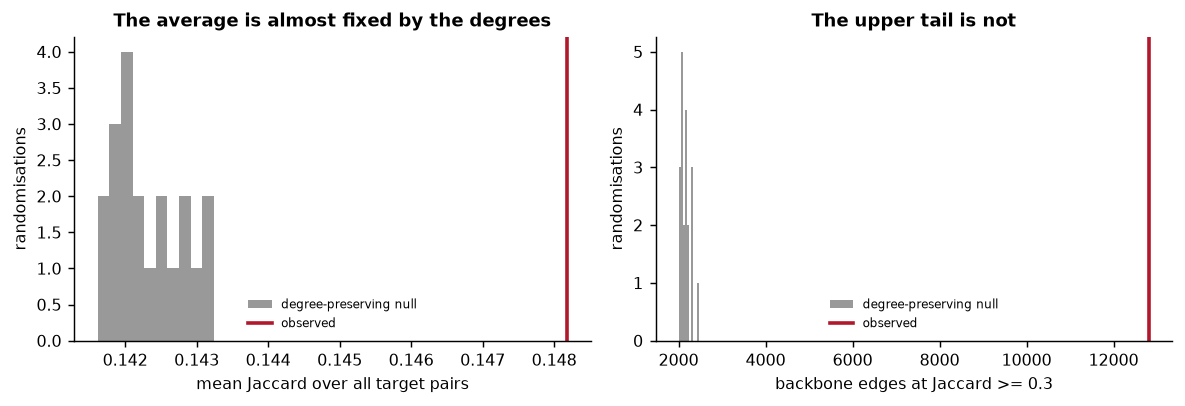

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.2))
axes[0].hist(null[:, 0], bins=10, color="#999999", label="degree-preserving null")
axes[0].axvline(observed[0], color="#b2182b", lw=2, label="observed")
axes[0].set_xlabel("mean Jaccard over all target pairs"); axes[0].set_ylabel("randomisations")
axes[0].set_title("The average is almost fixed by the degrees"); axes[0].legend(fontsize=6.5, frameon=False)
axes[1].hist(null[:, 1], bins=10, color="#999999", label="degree-preserving null")
axes[1].axvline(observed[1], color="#b2182b", lw=2, label="observed")
axes[1].set_xlabel("backbone edges at Jaccard >= 0.3"); axes[1].set_ylabel("randomisations")
axes[1].set_title("The upper tail is not"); axes[1].legend(fontsize=6.5, frameon=False)
fig.tight_layout(); plt.show()

<p class="caption"><b>Figure 4.</b> Observed statistics (red) against twenty degree-preserving randomisations of the
same bipartite graph (grey). Left: the mean Jaccard over all 114,481 target pairs is 0.1482 observed against
0.1423 +/- 0.0005 randomised - a z of 12, but an effect of 4 % that no one should build an argument on. Right: the
number of backbone edges at Jaccard 0.3 is 12,810 observed against 2,161 +/- 110 randomised, z = 97 and a six-fold
excess. The structure of this network lives entirely in the upper tail of the Jaccard distribution; the average is
essentially a restatement of the degree sequence.</p>

That contrast is the practical lesson of null modelling. Two summaries of the same projection, computed from the same
randomisations, support completely different conclusions: one says the targets share chemistry about as much as their
degrees force them to, the other says that specific pairs share far more than that. Report the statistic you tested,
the null that produced it and the number of randomisations - and prefer a statistic with a tail, because that is
where structure hides.

## 6. ROCK1 against ROCK2: a selectivity question asked of the data

Isoform selectivity is the question the group's ROCK programme actually faces. The bipartite graph says 276 compounds
have been measured at both kinases; the edge weights say how potent each is at each. The selectivity of a compound is
the difference of the two pChEMBL values, and a difference of 1 means a tenfold preference.

In [12]:
piv = edges.pivot_table(index="molecule_chembl_id", columns="target_chembl_id", values="pchembl_median")
both = piv[[ROCK1, ROCK2]].dropna()
delta = both[ROCK1] - both[ROCK2]
print("compounds measured at BOTH ROCK1 and ROCK2: %d (ROCK1 only: %d, ROCK2 only: %d)"
      % (len(both), len(set(B[ROCK1]) - set(B[ROCK2])), len(set(B[ROCK2]) - set(B[ROCK1]))))
print("pROCK1 - pROCK2: mean %+.3f, median %+.3f, sd %.3f" % (delta.mean(), delta.median(), delta.std()))
print("Pearson correlation of the two potencies r = %.3f (Spearman %.3f)"
      % (both[ROCK1].corr(both[ROCK2]), both[ROCK1].corr(both[ROCK2], method="spearman")))
print("selective by more than 10-fold (|difference| > 1): %d compounds (%.1f %%)"
      % ((delta.abs() > 1).sum(), 100 * (delta.abs() > 1).mean()))
print("selective by more than 3-fold  (|difference| > 0.5): %d compounds (%.1f %%)"
      % ((delta.abs() > 0.5).sum(), 100 * (delta.abs() > 0.5).mean()))
print("most ROCK2-preferring: %s (%.2f log units) | most ROCK1-preferring: %s (%+.2f)"
      % (delta.idxmin(), delta.min(), delta.idxmax(), delta.max()))

compounds measured at BOTH ROCK1 and ROCK2: 276 (ROCK1 only: 68, ROCK2 only: 34)
pROCK1 - pROCK2: mean -0.498, median -0.420, sd 0.635
Pearson correlation of the two potencies r = 0.870 (Spearman 0.851)
selective by more than 10-fold (|difference| > 1): 43 compounds (15.6 %)
selective by more than 3-fold  (|difference| > 0.5): 114 compounds (41.3 %)
most ROCK2-preferring: CHEMBL5281966 (-3.55 log units) | most ROCK1-preferring: CHEMBL2023159 (+0.88)


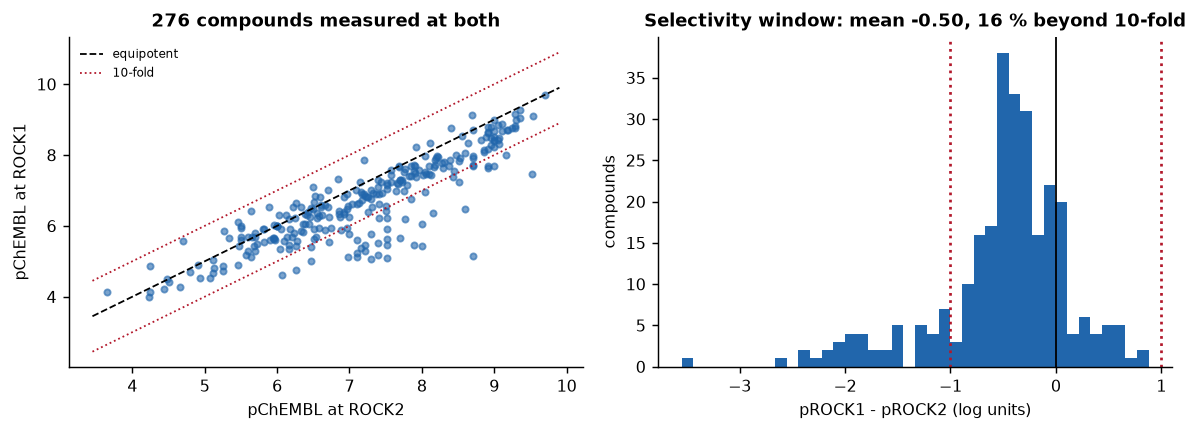

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.4))
axes[0].scatter(both[ROCK2], both[ROCK1], s=12, alpha=0.6, color="#2166ac")
lims = [min(both.min()) - 0.2, max(both.max()) + 0.2]
axes[0].plot(lims, lims, "k--", lw=1, label="equipotent")
axes[0].plot(lims, [v + 1 for v in lims], ":", c="#b2182b", lw=1, label="10-fold")
axes[0].plot(lims, [v - 1 for v in lims], ":", c="#b2182b", lw=1)
axes[0].set_xlabel("pChEMBL at ROCK2"); axes[0].set_ylabel("pChEMBL at ROCK1")
axes[0].set_title("276 compounds measured at both"); axes[0].legend(fontsize=6.5, frameon=False)
axes[1].hist(delta, bins=40, color="#2166ac")
axes[1].axvline(0, c="k", lw=1); axes[1].axvline(1, ls=":", c="#b2182b"); axes[1].axvline(-1, ls=":", c="#b2182b")
axes[1].set_xlabel("pROCK1 - pROCK2 (log units)"); axes[1].set_ylabel("compounds")
axes[1].set_title("Selectivity window: mean %+.2f, 16 %% beyond 10-fold" % delta.mean())
fig.tight_layout(); plt.show()

<p class="caption"><b>Figure 5.</b> Left: potency at ROCK1 against potency at ROCK2 for the 276 compounds measured at
both; the cloud sits on the diagonal (r = 0.87) and inside the tenfold band. Right: the distribution of the
difference, centred at -0.50 log units - this chemical series is on average slightly more potent at ROCK2 - with
15.6 % of compounds beyond tenfold selectivity in one direction or the other and a single outlier at -3.55.</p>

Three conclusions follow, and the third is the one a project needs. First, isoform selectivity within the ROCK family
is hard: the two kinases rank compounds almost identically (Spearman 0.85), as their near-identical ATP pockets
predict. Second, the few genuinely selective compounds are the interesting ones, and they are identifiable by name
from this table - which is how a selectivity programme starts. Third, the absence of an edge is not evidence: 68
compounds are measured at ROCK1 and not at ROCK2 and 34 the other way round, and nothing in the graph says whether
those are inactive or simply untested. A selectivity claim needs the measurement, not the missing edge.

In [14]:
profile = edges.pivot_table(index="molecule_chembl_id", columns="target_chembl_id", values="pchembl_median")
n_targets = profile.notna().sum(axis=1)
broad = profile.index[n_targets >= 20]
gap = {}
for c in broad:
    v = profile.loc[c].dropna().sort_values(ascending=False)
    gap[c] = v.iloc[0] - v.iloc[9]          # best minus tenth-best: a panel-wide selectivity index
gap = pd.Series(gap)
print("compounds measured at 20 or more targets: %d" % len(gap))
print("selectivity index (best minus 10th best pChEMBL): median %.2f, 10th percentile %.2f, 90th percentile %.2f"
      % (gap.median(), gap.quantile(0.1), gap.quantile(0.9)))
print("flat profiles (index < 0.5 log units, i.e. genuinely promiscuous): %d of %d (%.0f %%)"
      % ((gap < 0.5).sum(), len(gap), 100 * (gap < 0.5).mean()))
print("Spearman(selectivity index, number of targets measured) = %.3f" % spearmanr(gap, n_targets[gap.index]).statistic)
print("most selective broadly profiled compound: %s (index %.2f)" % (gap.idxmax(), gap.max()))

compounds measured at 20 or more targets: 174
selectivity index (best minus 10th best pChEMBL): median 1.47, 10th percentile 0.72, 90th percentile 2.48
flat profiles (index < 0.5 log units, i.e. genuinely promiscuous): 4 of 174 (2 %)
Spearman(selectivity index, number of targets measured) = -0.379
most selective broadly profiled compound: CHEMBL3600873 (index 3.27)


A single pair of targets is not the whole selectivity question, and the same table answers the panel-wide version.
For the 174 compounds measured at twenty targets or more, the gap between the best and the tenth-best pChEMBL is a
usable selectivity index: its median is 1.47 log units, its tenth percentile 0.72 and its ninetieth 2.48, and only
four compounds (2 %) have a profile flat enough to call genuinely promiscuous. The index falls as the number of
measured targets grows (Spearman -0.38), which is the assay-effort bias again: the more panels a compound has been
through, the more likely one of them found a second potent target. Report a selectivity index together with the
number of targets it was computed over, exactly as an enrichment factor is reported with its prevalence.

## 7. Link prediction, and the negative set that decides the answer

Link prediction asks which absent edges are most likely to be present but unobserved - in a drug-target graph, which
compound-target pairs are untested but plausible<sup class="c"><a href="#r18">[18]</a></sup><sup class="c"><a href="#r19">[19]</a></sup>.
The protocol is that of Unit 12 transplanted to graphs: hide a random 10 % of the edges, score candidate pairs using
only the remaining graph, and measure how well the hidden edges are recovered.

In a bipartite graph the familiar scores need one adjustment: a compound and a target have no common neighbours, so
the shortest informative path has length three (compound - target - compound - target). The three baselines below
are the natural bipartite analogues. **Path count** counts the three-step paths between the pair,
$(A A^{\mathsf T} A)_{ct}$ in matrix form. **Profile similarity** replaces the inner count by the cosine similarity
of the two compounds' target profiles, so that a compound tested at everything does not dominate. **Preferential
attachment**<sup class="c"><a href="#r17">[17]</a></sup> multiplies the two degrees and ignores structure entirely -
it is in the panel as a control, because if it scores as well as the others, the others are measuring popularity.

The negatives decide the answer. Uniformly drawn non-edges are mostly pairs of a rarely tested compound with a
rarely tested target, which any degree-aware score separates trivially. The honest alternative pairs each hidden
edge's compound with a target of **similar degree** to the true one, so that the popularity shortcut is removed.

In [15]:
def roc_auc(y, s):
    y = np.asarray(y); r = rankdata(s); n1 = y.sum(); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

rng_lp = np.random.default_rng(1)
present = np.argwhere(A > 0)
hidden_idx = rng_lp.choice(len(present), int(0.1 * len(present)), replace=False)
positives = present[hidden_idx]
A_train = A.copy()
for c, t in positives:
    A_train[c, t] = 0.0

A_norm = A_train / np.maximum(A_train.sum(axis=1, keepdims=True), 1)
S_path = A_train @ (A_train.T @ A_train)              # three-step path count
S_prof = (A_norm @ A_norm.T) @ A_train                # profile-similarity weighted
S_pref = np.outer(A_train.sum(axis=1), A_train.sum(axis=0))   # preferential attachment (degree product)

absent = np.argwhere(A == 0)
easy_neg = absent[rng_lp.choice(len(absent), 20 * len(positives), replace=False)]
tdeg_tr = A_train.sum(axis=0); order = np.argsort(tdeg_tr)
hard_neg = []
for c, t in positives[rng_lp.choice(len(positives), 20 * len(positives))]:
    lo = max(0, np.searchsorted(tdeg_tr[order], tdeg_tr[t]) - 15)
    cand = [x for x in order[lo:lo + 30] if A[c, x] == 0]
    if cand:
        hard_neg.append((c, int(rng_lp.choice(cand))))
hard_neg = np.array(hard_neg)
print("hidden edges %d | uniform negatives %d | degree-matched negatives %d"
      % (len(positives), len(easy_neg), len(hard_neg)))

def evaluate(negatives, label):
    cand = np.vstack([positives, negatives])
    y = np.r_[np.ones(len(positives)), np.zeros(len(negatives))]
    print("\n%s (prevalence %.3f)" % (label, y.mean()))
    out = {}
    for nm, S in [("3-step path count", S_path), ("profile similarity", S_prof), ("preferential attachment", S_pref)]:
        s = S[cand[:, 0], cand[:, 1]]
        o = np.argsort(-s, kind="mergesort")
        out[nm] = (roc_auc(y, s), y[o][:len(positives)].mean(), y, s)
        print("   %-24s ROC-AUC %.3f | precision@%d %.3f" % (nm, out[nm][0], len(positives), out[nm][1]))
    return out

easy = evaluate(easy_neg, "negatives drawn uniformly at random")
hard = evaluate(hard_neg, "negatives matched on target degree")

hidden edges 1604 | uniform negatives 32080 | degree-matched negatives 31493

negatives drawn uniformly at random (prevalence 0.048)
   3-step path count        ROC-AUC 0.918 | precision@1604 0.524
   profile similarity       ROC-AUC 0.707 | precision@1604 0.110
   preferential attachment  ROC-AUC 0.913 | precision@1604 0.502

negatives matched on target degree (prevalence 0.048)
   3-step path count        ROC-AUC 0.566 | precision@1604 0.105
   profile similarity       ROC-AUC 0.593 | precision@1604 0.140
   preferential attachment  ROC-AUC 0.516 | precision@1604 0.068


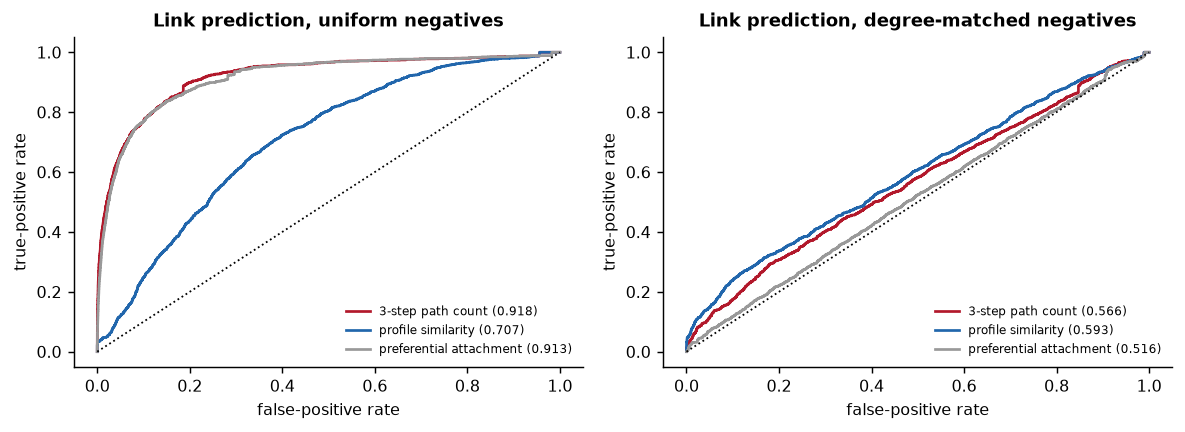

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.4))
def roc_points(y, s):
    o = np.argsort(-s, kind="mergesort"); ys = np.asarray(y)[o]
    tp = np.cumsum(ys); fp = np.cumsum(1 - ys)
    return np.r_[0, fp / fp[-1]], np.r_[0, tp / tp[-1]]
for ax, res, title in zip(axes, [easy, hard], ["uniform negatives", "degree-matched negatives"]):
    for (nm, (auc, prec, y, s)), col in zip(res.items(), ["#b2182b", "#2166ac", "#999999"]):
        fpr, tpr = roc_points(y, s)
        ax.plot(fpr, tpr, lw=1.5, color=col, label="%s (%.3f)" % (nm, auc))
    ax.plot([0, 1], [0, 1], "k:", lw=1)
    ax.set_xlabel("false-positive rate"); ax.set_ylabel("true-positive rate")
    ax.set_title("Link prediction, " + title); ax.legend(fontsize=6.5, frameon=False, loc="lower right")
fig.tight_layout(); plt.show()

<p class="caption"><b>Figure 6.</b> The same three predictors, the same 1,604 hidden edges, two negative sets.
Against uniformly drawn non-edges the path count reaches ROC-AUC 0.918 and recovers 52 % of the top 1,604 pairs -
but preferential attachment, which sees nothing except the two degrees, reaches 0.913, which is the tell. Against
negatives matched on target degree, the path count falls to 0.566, profile similarity to 0.593 and preferential
attachment to 0.516: with the popularity shortcut removed, these baselines are barely better than guessing.</p>

The conclusion generalises far beyond graphs: **a benchmark is as hard as its negatives**. A published AUC of 0.92
for drug-target link prediction may be measuring nothing but which targets are frequently assayed; the only way to
find out is to re-run it against degree-matched negatives, which costs ten lines. Unit 19 made the same point with
property-matched decoys - here the matching variable is degree instead of molecular weight. The practical
recommendation for this data set is the one the numbers support: use the network to *rank which untested pair to
measure next* only if a degree-matched evaluation shows the ranking beats popularity, and otherwise admit that the
model is recommending the targets everyone already screens.

## 8. Does sharing targets mean looking alike?

The unit's second graph is the chemical-similarity network of Unit 15: compounds joined when their Morgan
fingerprints<sup class="c"><a href="#r29">[29]</a></sup> are similar. It earns its place here by answering a question
the drug-target graph cannot: is the target profile of a compound predictable from its structure? Similarity-based
target inference - the similarity ensemble approach<sup class="c"><a href="#r8">[8]</a></sup><sup class="c"><a href="#r9">[9]</a></sup>
and the pharmacological-space mapping that preceded it<sup class="c"><a href="#r10">[10]</a></sup> - assumes it is.
With measured profiles for 602 compounds we can check the assumption instead of inheriting it.

In [17]:
cur = load_data("rock1_chembl_curated.csv")
smiles = {}                                    # one curated row can list several ChEMBL ids
for ids, smi in zip(cur["chembl_ids"].astype(str), cur["std_smiles"]):
    for cid in ids.replace(" ", "").replace(";", "|").split("|"):
        smiles[cid] = smi
print("curated structures available for %d of the %d network compounds"
      % (sum(c in smiles for c in compounds), len(compounds)))
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fps = [gen.GetFingerprint(Chem.MolFromSmiles(smiles[c])) for c in compounds]
n = len(compounds)
T = np.zeros((n, n), dtype=np.float32)
for i in range(n - 1):
    T[i, i + 1:] = DataStructs.BulkTanimotoSimilarity(fps[i], fps[i + 1:])
T = T + T.T
C = A @ A.T; d = np.diag(C).copy()
union = d[:, None] + d[None, :] - C
with np.errstate(divide="ignore", invalid="ignore"):
    Jc = np.where(union > 0, C / union, 0.0)
np.fill_diagonal(Jc, 0.0)
iu = np.triu_indices(n, 1)
print("%d compound pairs with both a fingerprint similarity and a measured target profile" % len(iu[0]))
print("Spearman(Tanimoto, target-profile Jaccard) = %.3f" % spearmanr(T[iu], Jc[iu]).statistic)
print("mean Tanimoto for pairs sharing >= 50 %% of their targets: %.3f | sharing < 10 %%: %.3f"
      % (T[iu][Jc[iu] >= 0.5].mean(), T[iu][Jc[iu] < 0.1].mean()))
print("pairs with Tanimoto >= 0.6: %d | their mean target-profile Jaccard %.3f (all pairs %.3f)"
      % ((T[iu] >= 0.6).sum(), Jc[iu][T[iu] >= 0.6].mean(), Jc[iu].mean()))

curated structures available for 602 of the 602 network compounds
180901 compound pairs with both a fingerprint similarity and a measured target profile
Spearman(Tanimoto, target-profile Jaccard) = 0.282
mean Tanimoto for pairs sharing >= 50 % of their targets: 0.228 | sharing < 10 %: 0.131
pairs with Tanimoto >= 0.6: 1114 | their mean target-profile Jaccard 0.826 (all pairs 0.163)


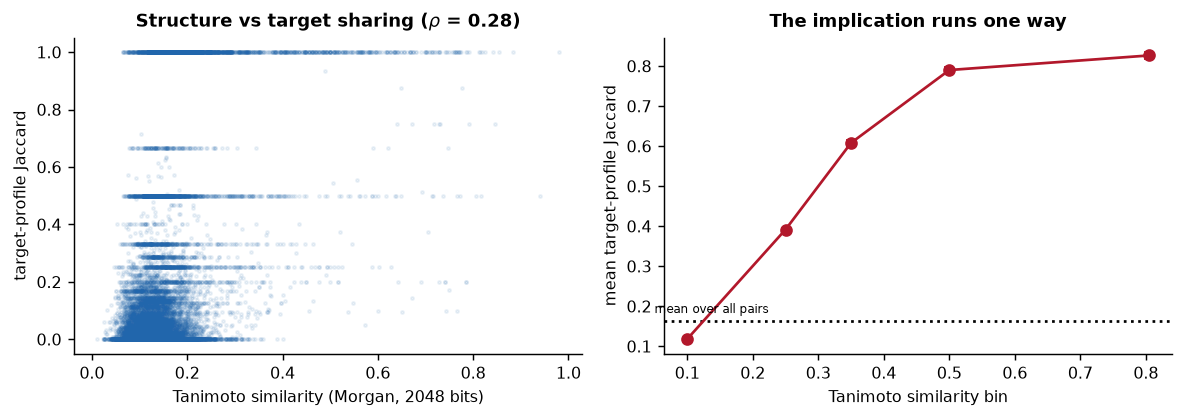

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.3))
samp = np.random.default_rng(0).choice(len(iu[0]), 20000, replace=False)
axes[0].scatter(T[iu][samp], Jc[iu][samp], s=3, alpha=0.08, color="#2166ac")
axes[0].set_xlabel("Tanimoto similarity (Morgan, 2048 bits)"); axes[0].set_ylabel("target-profile Jaccard")
axes[0].set_title(r"Structure vs target sharing ($\rho$ = 0.28)")
bins = [(0, 0.2), (0.2, 0.3), (0.3, 0.4), (0.4, 0.6), (0.6, 1.01)]
mids, means, errs = [], [], []
for lo, hi in bins:
    m = (T[iu] >= lo) & (T[iu] < hi)
    mids.append((lo + hi) / 2); means.append(Jc[iu][m].mean()); errs.append(Jc[iu][m].std() / np.sqrt(m.sum()))
axes[1].errorbar(mids, means, yerr=errs, fmt="o-", color="#b2182b", capsize=3)
axes[1].axhline(Jc[iu].mean(), ls=":", c="k")
axes[1].text(0.05, Jc[iu].mean() + 0.02, "mean over all pairs", fontsize=6.5)
axes[1].set_xlabel("Tanimoto similarity bin"); axes[1].set_ylabel("mean target-profile Jaccard")
axes[1].set_title("The implication runs one way")
fig.tight_layout(); plt.show()

<p class="caption"><b>Figure 7.</b> Left: every tenth compound pair, fingerprint similarity against the Jaccard
overlap of their measured target sets; the rank correlation over all 180,901 pairs is 0.28. Right: the same data
binned - pairs below Tanimoto 0.2 share 16 % of their targets on average, pairs above 0.6 share 83 %.</p>

The relation is strong in one direction and weak in the other, which is exactly what similarity-based target
inference assumes and what a careless reading of a correlation of 0.28 would miss. **Chemically similar compounds do
have similar target profiles** - above Tanimoto 0.6 the mean overlap is five times the baseline - so predicting
targets for a close analogue of a profiled compound is sound. **Dissimilar compounds often share targets anyway**,
because a kinase hinge binder can be reached from many chemotypes, so a low similarity is not evidence of a
different profile. In network terms: chemical similarity is a sufficient but not a necessary condition for an edge
to be shared, and a similarity network is therefore a conservative, high-precision proxy for the measured one.

## 9. Drawing a network, and when not to

A network figure is worth its space when the reader can extract something from the *positions* and the *shapes*.
Spring layouts of a thousand nodes - the hairball - almost never qualify: the layout is a stochastic compromise, a
change of seed moves everything, and no quantity can be read off reliably. Three cases justify a drawing: a small
graph; one neighbourhood shown at a readable scale and coloured by an attribute; and a schematic of a mechanism.
Anything else is better as a table or a distribution, and for interactive exploration
Cytoscape<sup class="c"><a href="#r21">[21]</a></sup> is the standard export target (`nx.write_graphml`). The test
before drawing is to ask which sentence of the results section the figure supports: if that sentence is a number -
a count of communities, a modularity, an enrichment - a table states it better; if it is a shape, the drawing is the
evidence and must be large enough to read.

In [19]:
nx.set_node_attributes(core, {t_: str(tname.get(t_, "")) for t_ in core}, "target_name")
nx.set_node_attributes(core, {t_: int(core.degree(t_)) for t_ in core}, "backbone_degree")
nx.set_node_attributes(core, {t_: int(i) for i, c in enumerate(communities) for t_ in c}, "community")
graphml = "\n".join(nx.generate_graphml(core))
print("GraphML export of the backbone: %d characters, %d node elements, %d edge elements"
      % (len(graphml), graphml.count("<node "), graphml.count("<edge ")))
print("first node element:\n ", [ln.strip() for ln in graphml.splitlines() if ln.strip().startswith("<node ")][0])
print("\nnx.write_graphml(core, 'backbone.graphml') would write exactly this file for Cytoscape.")

GraphML export of the backbone: 1464108 characters, 437 node elements, 12810 edge elements
first node element:
  <node id="CHEMBL1075102">

nx.write_graphml(core, 'backbone.graphml') would write exactly this file for Cytoscape.


sub-network drawn: 72 nodes, 477 edges


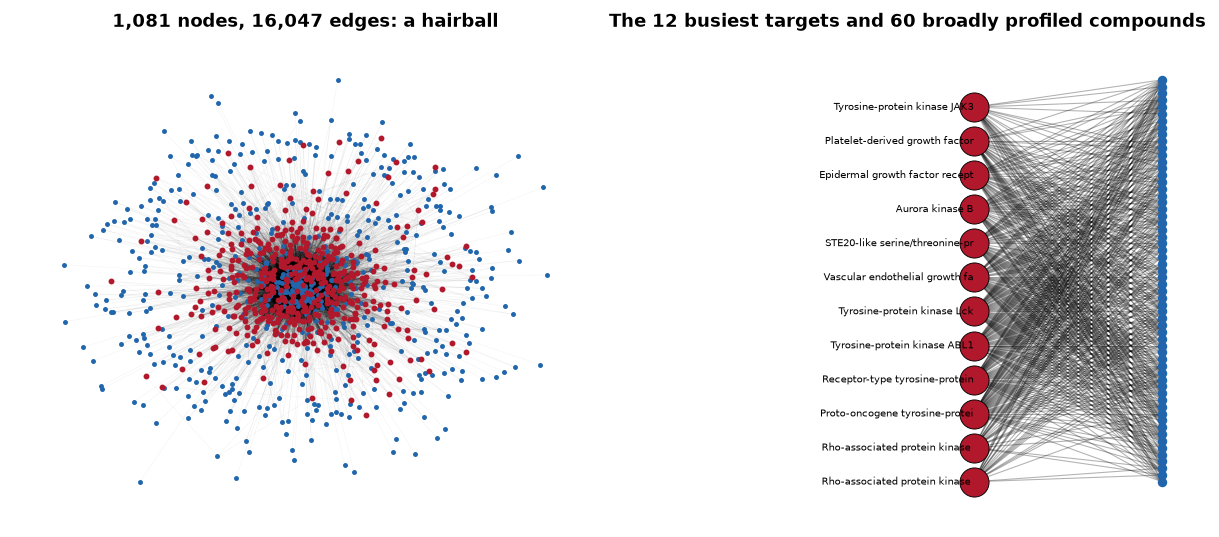

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(9.4, 4.2))
pos_all = nx.spring_layout(B, seed=0, k=0.06, iterations=25)
nx.draw_networkx_edges(B, pos_all, alpha=0.05, width=0.3, ax=axes[0])
nx.draw_networkx_nodes(B, pos_all, nodelist=compounds, node_size=3, node_color="#2166ac", ax=axes[0])
nx.draw_networkx_nodes(B, pos_all, nodelist=targets, node_size=5, node_color="#b2182b", ax=axes[0])
axes[0].set_title("1,081 nodes, 16,047 edges: a hairball"); axes[0].axis("off")

top_t = sorted(targets, key=lambda x: -B.degree(x))[:12]
sel_c = [c for c in compounds if sum(B.has_edge(c, t) for t in top_t) >= 6][:60]
S = B.subgraph(top_t + sel_c).copy()
pos = {t: (0.0, i) for i, t in enumerate(sorted(top_t, key=lambda x: -B.degree(x)))}
pos.update({c: (1.0, i * len(top_t) / max(1, len(sel_c))) for i, c in enumerate(sel_c)})
nx.draw_networkx_edges(S, pos, alpha=0.3, width=0.6, ax=axes[1])
nx.draw_networkx_nodes(S, pos, nodelist=top_t, node_size=260, node_color="#b2182b", edgecolors="k",
                       linewidths=0.5, ax=axes[1])
nx.draw_networkx_nodes(S, pos, nodelist=sel_c, node_size=18, node_color="#2166ac", ax=axes[1])
nx.draw_networkx_labels(S, pos, {t: str(tname.get(t))[:30] for t in top_t}, font_size=5.5,
                        horizontalalignment="right", ax=axes[1])
axes[1].set_xlim(-1.9, 1.2); axes[1].axis("off")
axes[1].set_title("The 12 busiest targets and %d broadly profiled compounds" % len(sel_c))
fig.tight_layout(); plt.show()
print("sub-network drawn: %d nodes, %d edges" % (S.number_of_nodes(), S.number_of_edges()))

<p class="caption"><b>Figure 8.</b> The same data drawn twice. Left: all 1,081 nodes in a spring layout; dense,
unlabelled and dominated by layout artefacts. Right: the twelve busiest targets with the compounds profiled against
at least six of them, drawn as a labelled bipartite layout - here a reader can see that almost every broadly
profiled compound touches both ROCK kinases and most of the tyrosine kinases, which is the sentence this section
needs. The left panel belongs in no paper; the right panel is a figure.</p>

<div class="exercise"><h4>Exercise 3</h4>
<p>Export the backbone with <code>nx.write_graphml</code>, carrying the target name, degree and community index as
node attributes and the Jaccard weight as an edge attribute, and open it in Cytoscape. Then write the two-sentence
caption you would use if the figure had to show all 437 backbone targets instead of twelve - and explain why the
table of community sizes and kinase fractions from section 4 serves the reader better.</p></div>

## 10. Summary

This unit analysed a measured drug-target network: 602 compounds, 479 human single-protein targets, 16,047 activity
edges, one connected component, density 0.0275. Ninety-three per cent of the compounds bind more than one target -
real polypharmacology, with a median compound degree of 5 and a maximum of 386, and a median target degree of 26
against ROCK1's 344. Before any interpretation, two selection biases were measured rather than asserted: 79 % of the
targets are named "kinase" and carry 83 % of the edges, so the graph is a ROCK-kinase neighbourhood and not a sample
of pharmacological space; and the rank correlation between a compound's degree and the number of measurements behind
its edges is 0.93, so degree records assay effort at least as much as promiscuity. ChEMBL's protein-class annotation
was empty for all 479 targets, an annotation gap worked around with target names rather than hidden.

The target projection has 100,146 edges and density 0.875 untreated - no usable structure - and was reduced to a
backbone of 12,810 edges at Jaccard 0.3, leaving 42 targets isolated. Greedy modularity found 17 communities at
Q = 0.328, the two largest holding 179 and 177 targets of which 91 % and 79 % are named "kinase", plus a small
non-kinase community dominated by carbonic anhydrases and a four-member cytochrome P450 community - the
counter-screens and ADME panels of a kinase programme.
A bipartite degree-preserving null, written explicitly so that swaps exchange target endpoints, showed why both
numbers need a null: the mean Jaccard over target pairs is 0.1482 observed against 0.1423 +/- 0.0005 randomised
(z = 12, a 4 % effect), while the backbone holds 12,810 edges against 2,161 +/- 110 (z = 97, a six-fold excess). Structure
lives in the tail, not the average. Centrality told the same story about provenance: betweenness is led by ROCK1
(0.220) and ROCK2 (0.210) and then by the four most-assayed compounds.

The selectivity question was answered directly from the 276 compounds measured at both ROCK isoforms: potencies
correlate at r = 0.87 (Spearman 0.85), the mean difference is -0.50 log units in favour of ROCK2, 15.6 % of
compounds exceed tenfold selectivity and the extreme is -3.55; 68 compounds are measured at ROCK1 only and 34 at
ROCK2 only, so a missing edge is a missing experiment and not an inactivity. Link prediction gave the sharpest
methodological result: three-step path counting reaches ROC-AUC 0.918 against uniformly drawn negatives - but so
does preferential attachment at 0.913, which is the warning - and against negatives matched on target degree the
three baselines fall to 0.566, 0.593 and 0.516. Finally, comparing the two kinds of edge showed that chemical
similarity implies shared targets (pairs above Tanimoto 0.6 share 83 % of their targets against a 16 % baseline)
while the converse fails (overall Spearman 0.28), so a similarity network is a high-precision, low-recall proxy for
a measured one. The three habits to keep: state how every edge was defined and with which threshold; compare every
network statistic with a degree-preserving null before interpreting it; and choose the negatives of a graph
benchmark as carefully as the decoys of a screening benchmark. A real project adds the graphs this unit did not
download - STRING<sup class="c"><a href="#r7">[7]</a></sup> for protein interactions, Open
Targets<sup class="c"><a href="#r20">[20]</a></sup> for target-disease evidence,
Hetionet<sup class="c"><a href="#r6">[6]</a></sup> for a knowledge graph - and applies the same
machinery<sup class="c"><a href="#r22">[22]</a></sup><sup class="c"><a href="#r23">[23]</a></sup><sup class="c"><a href="#r24">[24]</a></sup>,
including the small-world and network-medicine framings<sup class="c"><a href="#r11">[11]</a></sup><sup class="c"><a href="#r25">[25]</a></sup>.

<div class="box bridge"><h4>Bridge</h4>
<p>Within this course: the fingerprints and similarity come from <a href="../U13_Features_Dimensionality/index.html">Unit 13</a>,
the clustering from <a href="../U15_Clustering/index.html">Unit 15</a>, the hold-out protocol from
<a href="../U12_Validation/index.html">Unit 12</a>, the permutation tests from
<a href="../U8_Hypothesis_Testing/index.html">Unit 8</a>, and the negative-set argument from
<a href="../U19_Virtual_Screening/index.html">Unit 19</a>; the omics counterpart of a neighbourhood test is in
<a href="../U21_Omics/index.html">Unit 21</a>, and the figure standards in
<a href="../U23_Communication/index.html">Unit 23</a>. In the sister courses: the targets and their structures are
introduced in <a href="../../BGM324/02_Protein_Structure_Prediction/index.html">BGM324 unit 2</a>
and the structure-based design context in
<a href="../../BGM324/04_Computer_Aided_Drug_Design/index.html">BGM324 unit 4</a>;
chemical similarity and chemical space are developed in
<a href="../../Cheminformatics/U8_Chemical_Space/index.html">Cheminformatics unit 8</a> and
<a href="../../Cheminformatics/U11_Similarity_SAR/index.html">unit 11</a>; the evaluation protocol behind
the link-prediction section is in
<a href="../../BGM411/Python/S1_Model_Evaluation/index.html">BGM411 (model evaluation)</a>.</p></div>

## 11. Self-assessment

<details><summary>1. Your bipartite projection has density 0.875. What went wrong, and what do you do?</summary>
<p>Nothing went wrong - projections of dense bipartite graphs are nearly complete, because almost every pair of
targets shares at least one compound. Threshold the projection into a backbone (here Jaccard 0.3, which keeps 12,810
of 100,146 edges), report the threshold, and check how many nodes it isolates (42 here).</p></details>

<details><summary>2. Why is the Jaccard coefficient preferable to the raw count of shared compounds as a projection weight?</summary>
<p>Because the raw count grows with the degrees: ROCK1 shares many compounds with everything simply because 344
compounds were measured against it. The Jaccard coefficient divides by the union, so a pair of small, highly
overlapping target sets can outrank a pair of large, weakly overlapping ones.</p></details>

<details><summary>3. The mean Jaccard is 4 % above its degree-preserving null but the backbone has six times more edges than the null. Which do you report?</summary>
<p>Both, and the explanation: the average is almost fixed by the degree sequence, while the excess is concentrated
in the upper tail. A statistic with a tail (number of strong links, modularity, a specific pair's overlap) is the one
worth testing; an average that a null reproduces to within 4 % carries almost no information.</p></details>

<details><summary>4. Why must a degree-preserving swap in a bipartite graph exchange endpoints on the same side?</summary>
<p>Because swapping across sides would create compound-compound or target-target edges and destroy the bipartite
structure, changing the object rather than randomising it. The swap used here takes two compound-target edges and
exchanges their targets, which preserves every degree on both sides.</p></details>

<details><summary>5. A compound has no edge to ROCK2. Is it ROCK1-selective?</summary>
<p>No conclusion is possible. The absence of an edge means no measurement with a pChEMBL value exists in this
extraction - 68 compounds here are measured at ROCK1 and not at ROCK2. Selectivity requires both measurements; the
276 compounds that have them are the only ones about which the question can be asked.</p></details>

<details><summary>6. Your link-prediction model reaches ROC-AUC 0.92. What is the first thing to check?</summary>
<p>How the negatives were drawn, and what a degree-only baseline scores. Here preferential attachment - the product
of the two degrees, which knows nothing about structure - reached 0.913 against uniform negatives, and against
degree-matched negatives every method collapsed to 0.52-0.59. A benchmark is as hard as its negatives.</p></details>

<details><summary>7. In a bipartite graph the usual common-neighbour score is always zero. Why, and what replaces it?</summary>
<p>A compound and a target are on opposite sides, so they have no neighbours in common; the shortest informative
path has length three. The bipartite analogues count three-step paths (compound - target - compound - target), or
weight them by the similarity of the two compounds' target profiles.</p></details>

<details><summary>8. Degree correlates with the number of measurements at Spearman 0.93. What does that do to a "most promiscuous compounds" list?</summary>
<p>It makes it mostly a list of the most thoroughly profiled compounds. To rank promiscuity one must condition on
assay effort - for instance by restricting to compounds screened in a common panel, or by modelling the hit rate
(targets hit divided by targets tested) rather than the raw degree.</p></details>

<details><summary>9. Your communities are 91 % kinases. Is that biology?</summary>
<p>It is provenance. The compounds were selected as ROCK1 ligands and were therefore assayed mainly in kinase
panels, so the graph can hardly contain anything else; 79 % of all targets in it are named "kinase". The community
structure faithfully describes the data set and says nothing about pharmacological space in general.</p></details>

<details><summary>10. ChEMBL returned no protein class for any target. How should the analysis report that?</summary>
<p>Explicitly: state the coverage (0 of 479 here), use a declared surrogate - a text match on the target name in
this unit - and label every class-based statement as derived from that surrogate. Silently dropping the annotation,
or quietly substituting another source without saying so, is what makes an analysis unreproducible.</p></details>

<details><summary>11. Chemical similarity and target sharing correlate at only 0.28, yet pairs above Tanimoto 0.6 share 83 % of their targets. Is similarity useful for target prediction?</summary>
<p>Yes, in one direction. High similarity implies a shared profile (high precision), so inferring targets for a
close analogue is sound; low similarity does not imply a different profile (low recall), because the same target can
be reached from unrelated chemotypes. Report the implication you rely on.</p></details>

<details><summary>12. What minimum information must accompany any network result?</summary>
<p>The node and edge definitions, every threshold used, the number of nodes and edges, the provenance and selection
rule of the data, the software and version, the null model with the number of randomisations, and - for link
prediction - how the negatives were sampled.</p></details>

## Glossary

<dl class="gloss">
<dt>Bipartite graph</dt><dd>A graph whose nodes split into two sets with edges only between the sets, such as compounds and targets.</dd>
<dt>Projection</dt><dd>Graph on one side of a bipartite network, joining two nodes that share a neighbour; weighted by shared counts or by a Jaccard coefficient.</dd>
<dt>Backbone</dt><dd>The subgraph left after discarding projection edges below a weight threshold; a projection is uninterpretable without one.</dd>
<dt>Degree</dt><dd>Number of edges at a node; here the number of targets a compound was measured at, or compounds a target was screened with.</dd>
<dt>pChEMBL</dt><dd>-log10 of the molar concentration of a measured activity (IC50, Ki, Kd); 7 means 100 nM, and one unit is a factor of ten.</dd>
<dt>Polypharmacology / selectivity</dt><dd>Binding several targets / preferring one target over its relatives; a tenfold preference is one pChEMBL unit.</dd>
<dt>Betweenness centrality</dt><dd>Fraction of shortest paths passing through a node; in a designed data set it reproduces the design before it reveals biology.</dd>
<dt>Eigenvector centrality</dt><dd>Importance defined recursively by the importance of neighbours; well defined only on a connected graph.</dd>
<dt>Modularity Q</dt><dd>Fraction of edges inside communities minus the fraction expected in a degree-preserving random graph.</dd>
<dt>Resolution limit</dt><dd>Inability of modularity maximisation to detect communities below a size that grows with the graph.</dd>
<dt>Degree-preserving randomisation</dt><dd>Rewiring that keeps every node's degree and destroys everything else; in a bipartite graph the swap must exchange endpoints on the same side.</dd>
<dt>Link prediction</dt><dd>Scoring absent edges by plausibility; bipartite baselines count three-step paths, weight them by profile similarity, or multiply degrees.</dd>
<dt>Hard negatives</dt><dd>Non-edges chosen to be plausible - here matched on target degree - rather than uniformly at random.</dd>
<dt>Assay-effort bias</dt><dd>Degree reflecting how much a node has been measured rather than its biology; here Spearman 0.93 between compound degree and number of measurements.</dd>
<dt>Annotation gap</dt><dd>A metadata field that is absent for part or all of the data (here protein class for 479 of 479 targets), to be reported and worked around explicitly.</dd>
</dl>

## References and further reading

<ol class="refs">
<li id="r1">Barabasi AL, Gulbahce N, Loscalzo J. Network medicine: a network-based approach to human disease. <em>Nat Rev Genet</em>. 2011;12(1):56-68. <a href="https://doi.org/10.1038/nrg2918">doi:10.1038/nrg2918</a></li>
<li id="r2">Hopkins AL. Network pharmacology: the next paradigm in drug discovery. <em>Nat Chem Biol</em>. 2008;4(11):682-690. <a href="https://doi.org/10.1038/nchembio.118">doi:10.1038/nchembio.118</a></li>
<li id="r3">Yildirim MA, Goh KI, Cusick ME, Barabasi AL, Vidal M. Drug-target network. <em>Nat Biotechnol</em>. 2007;25(10):1119-1126. <a href="https://doi.org/10.1038/nbt1338">doi:10.1038/nbt1338</a></li>
<li id="r4">Blondel VD, Guillaume JL, Lambiotte R, Lefebvre E. Fast unfolding of communities in large networks. <em>J Stat Mech</em>. 2008;2008(10):P10008. <a href="https://doi.org/10.1088/1742-5468/2008/10/P10008">doi:10.1088/1742-5468/2008/10/P10008</a></li>
<li id="r5">Traag VA, Waltman L, van Eck NJ. From Louvain to Leiden: guaranteeing well-connected communities. <em>Sci Rep</em>. 2019;9:5233. <a href="https://doi.org/10.1038/s41598-019-41695-z">doi:10.1038/s41598-019-41695-z</a></li>
<li id="r6">Himmelstein DS, Lizee A, Hessler C, et al. Systematic integration of biomedical knowledge prioritizes drugs for repurposing. <em>eLife</em>. 2017;6:e26726. <a href="https://doi.org/10.7554/eLife.26726">doi:10.7554/eLife.26726</a></li>
<li id="r7">Szklarczyk D, Kirsch R, Koutrouli M, et al. The STRING database in 2023: protein-protein association networks and functional enrichment analyses. <em>Nucleic Acids Res</em>. 2023;51(D1):D638-D646. <a href="https://doi.org/10.1093/nar/gkac1000">doi:10.1093/nar/gkac1000</a></li>
<li id="r8">Keiser MJ, Roth BL, Armbruster BN, Ernsberger P, Irwin JJ, Shoichet BK. Relating protein pharmacology by ligand chemistry. <em>Nat Biotechnol</em>. 2007;25(2):197-206. <a href="https://doi.org/10.1038/nbt1284">doi:10.1038/nbt1284</a></li>
<li id="r9">Keiser MJ, Setola V, Irwin JJ, et al. Predicting new molecular targets for known drugs. <em>Nature</em>. 2009;462(7270):175-181. <a href="https://doi.org/10.1038/nature08506">doi:10.1038/nature08506</a></li>
<li id="r10">Paolini GV, Shapland RHB, van Hoorn WP, Mason JS, Hopkins AL. Global mapping of pharmacological space. <em>Nat Biotechnol</em>. 2006;24(7):805-815. <a href="https://doi.org/10.1038/nbt1228">doi:10.1038/nbt1228</a></li>
<li id="r11">Newman MEJ. The structure and function of complex networks. <em>SIAM Rev</em>. 2003;45(2):167-256. <a href="https://doi.org/10.1137/S003614450342480">doi:10.1137/S003614450342480</a></li>
<li id="r12">Newman MEJ, Girvan M. Finding and evaluating community structure in networks. <em>Phys Rev E</em>. 2004;69(2):026113. <a href="https://doi.org/10.1103/PhysRevE.69.026113">doi:10.1103/PhysRevE.69.026113</a></li>
<li id="r13">Fortunato S, Barthelemy M. Resolution limit in community detection. <em>Proc Natl Acad Sci USA</em>. 2007;104(1):36-41. <a href="https://doi.org/10.1073/pnas.0605965104">doi:10.1073/pnas.0605965104</a></li>
<li id="r14">Clauset A, Newman MEJ, Moore C. Finding community structure in very large networks. <em>Phys Rev E</em>. 2004;70(6):066111. <a href="https://doi.org/10.1103/PhysRevE.70.066111">doi:10.1103/PhysRevE.70.066111</a></li>
<li id="r15">Barabasi AL, Albert R. Emergence of scaling in random networks. <em>Science</em>. 1999;286(5439):509-512. <a href="https://doi.org/10.1126/science.286.5439.509">doi:10.1126/science.286.5439.509</a></li>
<li id="r16">Maslov S, Sneppen K. Specificity and stability in topology of protein networks. <em>Science</em>. 2002;296(5569):910-913. <a href="https://doi.org/10.1126/science.1065103">doi:10.1126/science.1065103</a></li>
<li id="r17">Adamic LA, Adar E. Friends and neighbors on the Web. <em>Soc Networks</em>. 2003;25(3):211-230. <a href="https://doi.org/10.1016/S0378-8733(03)00009-1">doi:10.1016/S0378-8733(03)00009-1</a></li>
<li id="r18">Liben-Nowell D, Kleinberg J. The link-prediction problem for social networks. <em>J Am Soc Inf Sci Technol</em>. 2007;58(7):1019-1031. <a href="https://doi.org/10.1002/asi.20591">doi:10.1002/asi.20591</a></li>
<li id="r19">Lu L, Zhou T. Link prediction in complex networks: a survey. <em>Physica A</em>. 2011;390(6):1150-1170. <a href="https://doi.org/10.1016/j.physa.2010.11.027">doi:10.1016/j.physa.2010.11.027</a></li>
<li id="r20">Ochoa D, Hercules A, Carmona M, et al. The next-generation Open Targets Platform: reimagined, redesigned, rebuilt. <em>Nucleic Acids Res</em>. 2023;51(D1):D1353-D1359. <a href="https://doi.org/10.1093/nar/gkac1046">doi:10.1093/nar/gkac1046</a></li>
<li id="r21">Shannon P, Markiel A, Ozier O, et al. Cytoscape: a software environment for integrated models of biomolecular interaction networks. <em>Genome Res</em>. 2003;13(11):2498-2504. <a href="https://doi.org/10.1101/gr.1239303">doi:10.1101/gr.1239303</a></li>
<li id="r22">Guney E, Menche J, Vidal M, Barabasi AL. Network-based in silico drug efficacy screening. <em>Nat Commun</em>. 2016;7:10331. <a href="https://doi.org/10.1038/ncomms10331">doi:10.1038/ncomms10331</a></li>
<li id="r23">Menche J, Sharma A, Kitsak M, et al. Uncovering disease-disease relationships through the incomplete interactome. <em>Science</em>. 2015;347(6224):1257601. <a href="https://doi.org/10.1126/science.1257601">doi:10.1126/science.1257601</a></li>
<li id="r24">Cheng F, Kovacs IA, Barabasi AL. Network-based prediction of drug combinations. <em>Nat Commun</em>. 2019;10:1197. <a href="https://doi.org/10.1038/s41467-019-09186-x">doi:10.1038/s41467-019-09186-x</a></li>
<li id="r25">Watts DJ, Strogatz SH. Collective dynamics of 'small-world' networks. <em>Nature</em>. 1998;393(6684):440-442. <a href="https://doi.org/10.1038/30918">doi:10.1038/30918</a></li>
<li id="r26">Hagberg AA, Schult DA, Swart PJ. Exploring network structure, dynamics, and function using NetworkX. <em>Proc 7th Python in Science Conf</em>. 2008:11-15. <a href="https://doi.org/10.25080/TCWV9851">doi:10.25080/TCWV9851</a></li>
<li id="r27">Bemis GW, Murcko MA. The properties of known drugs. 1. Molecular frameworks. <em>J Med Chem</em>. 1996;39(15):2887-2893. <a href="https://doi.org/10.1021/jm9602928">doi:10.1021/jm9602928</a></li>
<li id="r28">Zdrazil B, Felix E, Hunter F, et al. The ChEMBL Database in 2023: a drug discovery platform spanning multiple bioactivity data types and time periods. <em>Nucleic Acids Res</em>. 2024;52(D1):D1180-D1192. <a href="https://doi.org/10.1093/nar/gkad1004">doi:10.1093/nar/gkad1004</a></li>
<li id="r29">Rogers D, Hahn M. Extended-connectivity fingerprints. <em>J Chem Inf Model</em>. 2010;50(5):742-754. <a href="https://doi.org/10.1021/ci100050t">doi:10.1021/ci100050t</a></li>
<li id="r30">Harris CR, Millman KJ, van der Walt SJ, et al. Array programming with NumPy. <em>Nature</em>. 2020;585:357-362. <a href="https://doi.org/10.1038/s41586-020-2649-2">doi:10.1038/s41586-020-2649-2</a></li>
<li id="r31">Virtanen P, Gommers R, Oliphant TE, et al. SciPy 1.0: fundamental algorithms for scientific computing in Python. <em>Nat Methods</em>. 2020;17:261-272. <a href="https://doi.org/10.1038/s41592-019-0686-2">doi:10.1038/s41592-019-0686-2</a></li>
<li id="r32">Hunter JD. Matplotlib: a 2D graphics environment. <em>Comput Sci Eng</em>. 2007;9(3):90-95. <a href="https://doi.org/10.1109/MCSE.2007.55">doi:10.1109/MCSE.2007.55</a></li>
<li id="r33">Pedregosa F, Varoquaux G, Gramfort A, et al. Scikit-learn: machine learning in Python. <em>J Mach Learn Res</em>. 2011;12:2825-2830. <a href="https://doi.org/10.48550/arXiv.1201.0490">doi:10.48550/arXiv.1201.0490</a></li>
</ol>

<h4>Textbooks</h4>
<ul>
<li>Barabasi AL. <em>Network Science</em>. Cambridge University Press; 2016. - Free online; degree distributions, random-graph nulls, communities and robustness.</li>
<li>Newman MEJ. <em>Networks</em>. 2nd ed. Oxford University Press; 2018. - The reference text for the descriptors used here.</li>
<li>Hastie T, Tibshirani R, Friedman J. <em>The Elements of Statistical Learning</em>. 2nd ed. Springer; 2009. - Chapter 17 for the statistical view of graphs.</li>
<li>Leach AR, Gillet VJ. <em>An Introduction to Chemoinformatics</em>. Rev. ed. Springer; 2007. - Similarity networks and chemical space.</li>
</ul>

<h4>Online resources</h4>
<ul>
<li>NetworkX documentation, including the bipartite algorithms used here: <a href="https://networkx.org/documentation/stable/reference/algorithms/bipartite.html">networkx.org bipartite reference</a>.</li>
<li>igraph and python-louvain for faster community detection on large graphs: <a href="https://python.igraph.org/">python.igraph.org</a>.</li>
<li>Cytoscape, for interactive inspection and publication-quality layouts: <a href="https://cytoscape.org/">cytoscape.org</a>.</li>
<li>ChEMBL, the source of the frozen drug-target table: <a href="https://www.ebi.ac.uk/chembl/">ebi.ac.uk/chembl</a>.</li>
<li>STRING, Open Targets and Hetionet, where a real project obtains interaction, target-disease and knowledge graphs: <a href="https://string-db.org/">string-db.org</a>, <a href="https://platform.opentargets.org/">platform.opentargets.org</a>, <a href="https://het.io/">het.io</a>.</li>
</ul>